# Implement Today Data preprocessing techniques on Different Dataset.
## 28/07/2026,  Day_12 Homework.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ipl = pd.read_csv("E:/AI_ML_Training/AI_ML/raw_materials/Day_11/IPL2025Batters_raw.csv")

In [3]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
ipl.head()

,Player Name,Team,Runs,matches,Inn,NO,HS,Avg,BF,SR,100s,50s,4s,6S
0,Marcus Stoinis,PBKS,160,13.0,11.0,5.0,NaN,26.67,86,186.04,0,0,8.0,15.0
1,Jamie Overton,csk,15,3.0,2.0,2.0,11*,-,7,NaN,0,0,1.0,1.0
2,Suryansh Shedge,PBKS,7,5.0,3.0,0.0,4,2.33,11,63.63,0,0,0.0,0.0
3,Tristan Stubbs,DC,300,14.0,13.0,7.0,41*,50.00,199,150.75,0,0,25.0,11.0
4,Quinton De Kock,KKR,152,8.0,8.0,1.0,97*,21.71,117,129.91,0,1,9.0,11.0


In [4]:
ipl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Player Name   164 non-null    object 
 1    Team         164 non-null    object 
 2   Runs          160 non-null    object 
 3   matches       164 non-null    float64
 4   Inn           164 non-null    float64
 5   NO            164 non-null    float64
 6   HS            161 non-null    object 
 7   Avg           159 non-null    object 
 8   BF            159 non-null    object 
 9   SR            156 non-null    float64
 10  100s          160 non-null    object 
 11  50s           160 non-null    object 
 12  4s            164 non-null    float64
 13  6S            164 non-null    float64
dtypes: float64(6), object(8)
memory usage: 18.3+ KB


In [5]:
ipl.shape

(166, 14)

In [6]:
ipl.isnull().sum()

Player Name      2
 Team            2
Runs             6
matches          2
Inn              2
NO               2
HS               5
Avg              7
BF               7
SR              10
100s             6
50s              6
4s               2
6S               2
dtype: int64

In [7]:
# By this information we can decide that which columns(features) are can drop from the dataset. If null percentage is greater than 20 than drop that columns.

null_val_perc = ipl.isnull().sum()/ipl.shape[0] * 100
null_val_perc

Player Name     1.204819
 Team           1.204819
Runs            3.614458
matches         1.204819
Inn             1.204819
NO              1.204819
HS              3.012048
Avg             4.216867
BF              4.216867
SR              6.024096
100s            3.614458
50s             3.614458
4s              1.204819
6S              1.204819
dtype: float64

<Axes: >

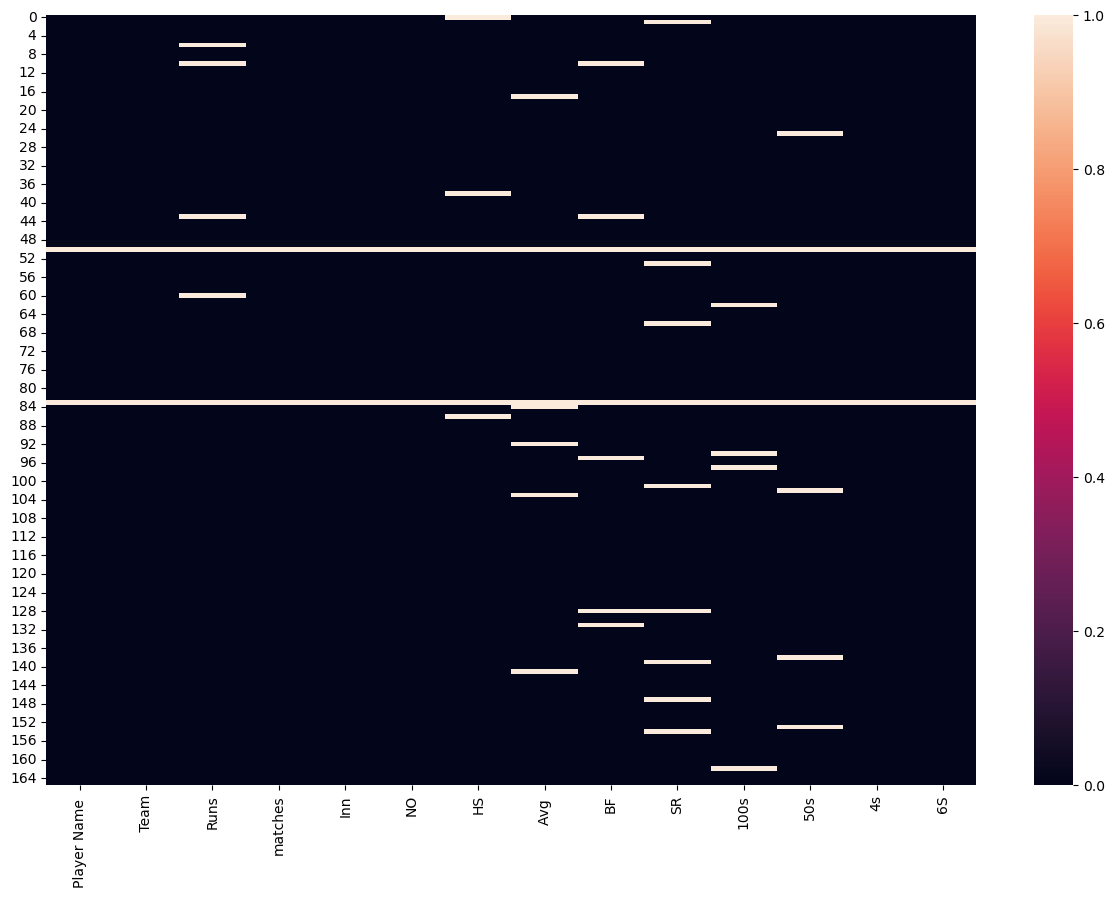

In [8]:
plt.figure(figsize= (15,10))
sns.heatmap(ipl.isnull())

In [9]:
## removing all the null values through the row. So a row that contain the null value will drop from the dataset.
ipl_rem = ipl.dropna()
ipl_rem.head()

,Player Name,Team,Runs,matches,Inn,NO,HS,Avg,BF,SR,100s,50s,4s,6S
2,Suryansh Shedge,PBKS,7,5.0,3.0,0.0,4,2.33,11,63.63,0,0,0.0,0.0
3,Tristan Stubbs,DC,300,14.0,13.0,7.0,41*,50.00,199,150.75,0,0,25.0,11.0
4,Quinton De Kock,KKR,152,8.0,8.0,1.0,97*,21.71,117,129.91,0,1,9.0,11.0
5,Rahmanullah Gurbaz,Kolkata Knight Riders,74,5.0,5.0,1.0,35,18.50,53,139.62,0,unknown,10.0,3.0
7,Manoj Bhandage,RCB,1,1.0,1.0,0.0,1,1.00,4,25.00,0,0,0.0,0.0


<Axes: >

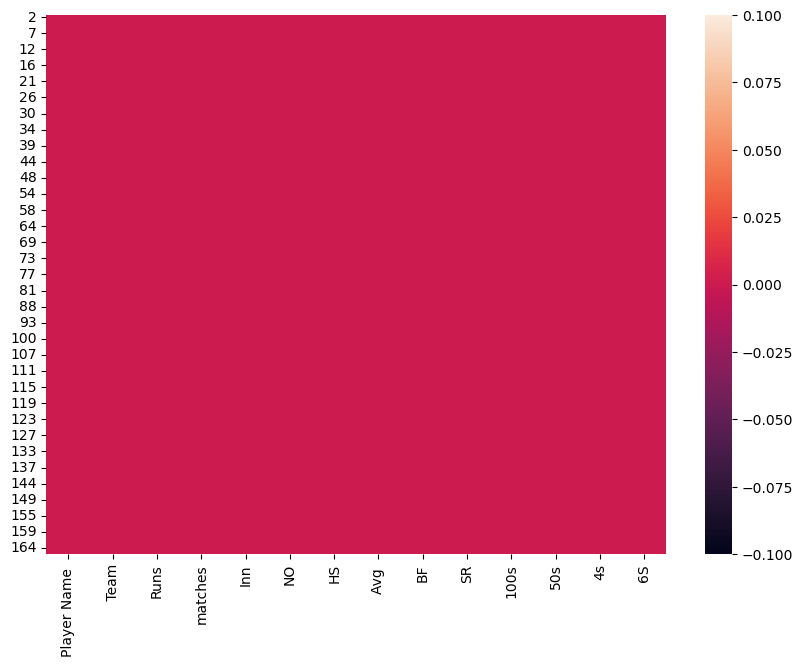

In [10]:
plt.figure(figsize= (10,7))
sns.heatmap(ipl_rem.isnull())

In [11]:
## Checking that is there any null values
ipl_rem.isnull().sum().sum()

np.int64(0)

## Numerical Value Data Distribution 

In [12]:
## here we select the columns that have numeric values
ipl_rem_num_col = ipl_rem.select_dtypes(include = ['int64', 'float64']).columns
ipl_rem_num_col

Index(['matches', 'Inn', 'NO', 'SR', '4s', '6S'], dtype='object')

C:\Users\Mahipal\AppData\Local\Temp\ipykernel_27868\1449741288.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ipl['SR'] )
C:\Users\Mahipal\AppData\Local\Temp\ipykernel_27868\1449741288.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ipl_rem['SR'])


<Axes: xlabel='SR', ylabel='Density'>

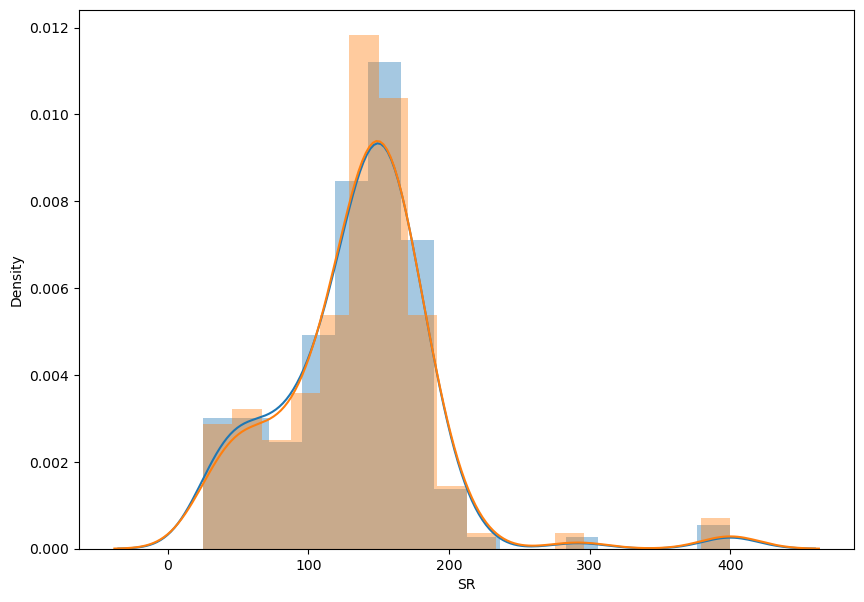

In [13]:
# checking the changes of data distribution after removing the null values

plt.figure(figsize= (10,7))
sns.distplot(ipl['SR'] )
sns.distplot(ipl_rem['SR'])

## Categorical data Distribution

In [15]:
ipl_rem_cat_col = ipl_rem.select_dtypes(include = ['O']).columns
ipl_rem_cat_col

Index(['Player Name ', ' Team', 'Runs', 'HS', 'Avg ', 'BF', '100s', '50s'], dtype='object')

In [17]:
ipl['50s'].value_counts()

50s
0          92
1          29
2          15
3           6
6           5
5           5
4           4
unknown     1
-           1
8           1
?           1
Name: count, dtype: int64

In [19]:
ipl['50s'].value_counts()/ipl_rem.shape[0] * 100

50s
0          68.656716
1          21.641791
2          11.194030
3           4.477612
6           3.731343
5           3.731343
4           2.985075
unknown     0.746269
-           0.746269
8           0.746269
?           0.746269
Name: count, dtype: float64

In [20]:
ipl_rem['50s'].value_counts()/ipl_rem.shape[0] * 100

50s
0          54.477612
1          20.895522
2           9.701493
5           3.731343
6           2.985075
4           2.985075
3           2.238806
unknown     0.746269
-           0.746269
8           0.746269
?           0.746269
Name: count, dtype: float64

In [21]:
pd.concat([ipl['50s'].value_counts()/ipl_rem.shape[0] * 100, ipl_rem['50s'].value_counts()/ipl_rem.shape[0] * 100],
          axis = 1,
         keys = ['50s_Org', '50s_Clean'])

,50s_Org,50s_Clean
50s,,
0,68.656716,54.477612
1,21.641791,20.895522
2,11.194030,9.701493
3,4.477612,2.238806
6,3.731343,2.985075
5,3.731343,3.731343
4,2.985075,2.985075
unknown,0.746269,0.746269
-,0.746269,0.746269


In [22]:
pd.concat([ipl['50s'].value_counts()/ipl.shape[0] * 100, ipl_rem['50s'].value_counts()/ipl_rem.shape[0] * 100],
          axis = 1,
         keys = ['50s_Org', '50s_Clean'])

,50s_Org,50s_Clean
50s,,
0,55.421687,54.477612
1,17.469880,20.895522
2,9.036145,9.701493
3,3.614458,2.238806
6,3.012048,2.985075
5,3.012048,3.731343
4,2.409639,2.985075
unknown,0.602410,0.746269
-,0.602410,0.746269


In [23]:
def categorical_var_dist(var):
    return pd.concat([ipl[var].value_counts()/ipl.shape[0]*100, ipl_rem[var].value_counts()/ipl_rem.shape[0]*100],
         axis = 1,
         keys = [var+'_Org', var+'_Clean'])

In [24]:
categorical_var_dist('100s')

,100s_Org,100s_Clean
100s,,
0,89.156627,93.283582
1,6.024096,5.223881
unknown,1.204819,1.492537


In [25]:
for name in ipl_rem_cat_col:
    print("="*50)
    print(f"columns --> {name}")
    print("="*50)
    print(categorical_var_dist(name), "\n")

columns --> Player Name 
                          Player Name _Org  Player Name _Clean
Player Name                                                   
Abdul  Samad                      1.204819                 NaN
Aniket Verma                      1.204819            1.492537
Mayank Agarwal                    1.204819            1.492537
Travis Head                       1.204819            0.746269
Rohit Sharma                      1.204819            1.492537
Tristan Stubbs                    0.602410            0.746269
Quinton De Kock                   0.602410            0.746269
Ruturaj Gaikwad                   0.602410                 NaN
Rahmanullah Gurbaz                0.602410            0.746269
Spencer Johnson                   0.602410            0.746269
Manoj Bhandage                    0.602410            0.746269
Rashid Khan                       0.602410            0.746269
Yash Dayal                        0.602410            0.746269
Jamie Overton                 